# 編集距離と n-gram 言語モデルによる誤り検出・訂正

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch3_edit_distance_lm.ipynb)

書籍 第3章「系列ラベリング問題の解き方」（3-3 誤り検出：誤り箇所の検出と訂正、p.104〜110、関連論文 3章・4章）に対応する演習ノートブックです。
CPU のみ・数秒で実行でき、GECToR などの深層学習手法の前段階となる古典的・基礎的な仕組みと、GEC 特有の編集スパン抽出・$F_{0.5}$ 評価までを体験します。

1. **編集距離（Levenshtein 距離）と隣接文字入れ替え（制約付き Damerau–Levenshtein 距離）**（3-3-1、脚注 42〜43）
2. **編集距離を用いたスペル訂正の候補ランキング**
3. **単語バイグラム言語モデルによる誤り検出** (3-3-2)
4. **編集距離と言語モデルを組み合わせた文脈スペル・誤字訂正（雑音のある通信路モデル）** (3-3)
5. **文法誤り訂正 (GEC) の編集スパン抽出（M2 / ERRANT 方式）とマルチリファレンス $F_{0.5}$ 評価**（3-3-3・関連論文 3章 10）
6. **発展：ノイズあり通信路モデルによる外来語の音訳（3-3 & 4-2-2 関連論文：Knight & Graehl 1997）**: 英語単語・音素・カタカナモーラの生成モデルをベイズ則で反転し、音韻 DP アライメントと英語言語モデルの統合効果を検証

## 1. 編集距離（Levenshtein 距離）の実装 (3-3-1)

2つの文字列 $A$（長さ $m$）と $B$（長さ $n$）の間で、「挿入・削除・置換」の最小操作回数を動的計画法（計算量 $O(mn)$）で求めます。
また、書籍 3-3-1（脚注 42〜43）で紹介されているように、キーボード入力では `the` を `hte` のように隣り合う 2 文字を入れ替える (swap) ミスがよく起きるため、入れ替えもコスト 1 と数える **制約付き Damerau–Levenshtein 距離 (OSA)** も実装して比較します。

In [1]:
import math
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def levenshtein_dp(a, b):
    '''Levenshtein 距離と DP テーブルを返す（計算量 O(mn)）'''
    m, n = len(a), len(b)
    dp = np.zeros((m + 1, n + 1), dtype=int)
    for i in range(m + 1):
        dp[i, 0] = i
    for j in range(n + 1):
        dp[0, j] = j
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            cost = 0 if a[i - 1] == b[j - 1] else 1
            dp[i, j] = min(
                dp[i - 1, j] + 1,       # 削除
                dp[i, j - 1] + 1,       # 挿入
                dp[i - 1, j - 1] + cost # 置換（一致なら 0）
            )
    return int(dp[m, n]), dp

def damerau_levenshtein(a, b):
    '''隣接文字の入れ替え（swap）もコスト 1 とする編集距離'''
    m, n = len(a), len(b)
    dp = np.zeros((m + 1, n + 1), dtype=int)
    for i in range(m + 1):
        dp[i, 0] = i
    for j in range(n + 1):
        dp[0, j] = j
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            cost = 0 if a[i - 1] == b[j - 1] else 1
            dp[i, j] = min(dp[i - 1, j] + 1, dp[i, j - 1] + 1, dp[i - 1, j - 1] + cost)
            if i > 1 and j > 1 and a[i - 1] == b[j - 2] and a[i - 2] == b[j - 1]:
                dp[i, j] = min(dp[i, j], dp[i - 2, j - 2] + 1)  # swap
    return int(dp[m, n])

dist, dp_table = levenshtein_dp("hte", "the")
print(f"Levenshtein('hte', 'the')         = {dist}")
print(f"OSA('hte', 'the') = {damerau_levenshtein('hte', 'the')}")

print("\nDP テーブル ('hte' -> 'the'):")
display(pd.DataFrame(dp_table, index=["#"] + list("hte"), columns=["#"] + list("the")))

Levenshtein('hte', 'the')         = 2
OSA('hte', 'the') = 1

DP テーブル ('hte' -> 'the'):


,#,t,h,e
#,0,1,2,3
h,1,1,1,2
t,2,1,2,2
e,3,2,2,2


---

## 2. 編集距離を使ったスペル訂正の候補ランキング

辞書（単語リスト）の中から、入力語との編集距離が小さい順に訂正候補を並べます。

In [2]:
vocab = ["the", "they", "there", "their", "them", "then", "heat", "hat", "language", "natural", "processing", "model"]

typos = ["hte", "langage", "natrual", "proccessing"]
for w in typos:
    ranked = sorted(vocab, key=lambda v: (damerau_levenshtein(w, v), levenshtein_dp(w, v)[0], v))[:3]
    scores = [(cand, damerau_levenshtein(w, cand), levenshtein_dp(w, cand)[0]) for cand in ranked]
    print(f"入力: {w:12s} -> 候補 (単語, OSA, Levenshtein): {scores}")

入力: hte          -> 候補 (単語, OSA, Levenshtein): [('the', 1, 2), ('hat', 2, 2), ('them', 2, 3)]
入力: langage      -> 候補 (単語, OSA, Levenshtein): [('language', 1, 1), ('hat', 6, 6), ('heat', 6, 6)]
入力: natrual      -> 候補 (単語, OSA, Levenshtein): [('natural', 1, 2), ('hat', 5, 5), ('language', 5, 5)]
入力: proccessing  -> 候補 (単語, OSA, Levenshtein): [('processing', 1, 1), ('model', 9, 9), ('their', 9, 9)]


---

## 3. n-gram 言語モデルによる誤り検出 (3-3-2)

単語単位のスペルが正しくても、文脈に合わない誤用（例：`I like an apple` vs `I like a apple`、`自然言語処理` vs `自然言語処置`）は辞書引きだけでは検出できません。
ここでは Add-k スムージング付きの単語バイグラム言語モデルを構築し、文の**パープレキシティ (Perplexity; PPL)**（低いほどトークンあたりの予測確率が高い）を比較してみます。

In [3]:
train_sents = [
    "<s> i like an apple </s>",
    "<s> i eat an apple every day </s>",
    "<s> i like a banana </s>",
    "<s> she likes a book </s>",
    "<s> he reads a book every day </s>",
    "<s> we study natural language processing </s>",
    "<s> natural language processing is fun </s>",
] * 20

unigram_counts = Counter()
bigram_counts = defaultdict(Counter)
vocab_lm = set()

for s in train_sents:
    toks = s.split()
    vocab_lm.update(toks)
    for i, tok in enumerate(toks):
        unigram_counts[tok] += 1
        if i > 0:
            bigram_counts[toks[i - 1]][tok] += 1

def bigram_perplexity(sent, k=0.1):
    toks = ["<s>"] + sent.lower().split() + ["</s>"]
    V = len(vocab_lm)
    log_prob = 0.0
    n = len(toks) - 1
    for i in range(1, len(toks)):
        prev_w, curr_w = toks[i - 1], toks[i]
        num = bigram_counts[prev_w][curr_w] + k
        den = unigram_counts[prev_w] + k * V
        log_prob += math.log(num / den)
    return math.exp(-log_prob / n)

test_sents = [
    ("自然な文 1", "i like an apple"),
    ("誤りを含む文 1（冠詞ミス）", "i like a apple"),
    ("自然な文 2", "natural language processing is fun"),
    ("誤りを含む文 2（語順ミス）", "language natural is processing fun"),
]

rows = []
for label, s in test_sents:
    rows.append({"ケース": label, "文": s, "Perplexity (低いほど自然)": round(bigram_perplexity(s), 2)})
pd.DataFrame(rows)

,ケース,文,Perplexity (低いほど自然)
0,自然な文 1,i like an apple,1.77
1,誤りを含む文 1（冠詞ミス）,i like a apple,6.33
2,自然な文 2,natural language processing is fun,1.65
3,誤りを含む文 2（語順ミス）,language natural is processing fun,172.83


---

## 4. 編集距離と n-gram 言語モデルを組み合わせた文脈スペル・誤字訂正 (3-3)

第 2 節の「編集距離のみ」の訂正は文脈を見ないため、同じ最小編集距離の候補が複数あるとき（例: `wat` → `cat` / `eat` / `hat` / `mat`）に適切な候補を選べず、また語彙に存在する**実単語誤り (real-word error)**（例: `i like a apple` の `a`、`she reads form a book` の `form`）も検出・訂正できません。一方、第 3 節の「言語モデルのみ」では誤りの検出（パープレキシティ上昇）はできても訂正候補を作れません。

そこで両者を統合する古典的手法が**雑音のある通信路モデル** (Noisy Channel Model) です。入力文 $x = (x_1, \dots, x_T)$ に対し、元の正しい文 $w = (w_1, \dots, w_T)$ を事後確率最大 (MAP) で推定します。

$$\hat{w} = \arg\max_{w} P(w \mid x) = \arg\max_{w} P(x \mid w)\, P(w)$$

対数確率で書くと、**通信路（誤り）モデル**と**言語モデル**の和の最大化になります。

$$\log P(x \mid w) + \log P(w) = \sum_{t=1}^{T} \log P(x_t \mid w_t) + \sum_{t=1}^{T+1} \log P(w_t \mid w_{t-1})$$

- **通信路モデル $P(x_t \mid w_t)$**: 各単語位置で OSA 距離 $\le 1$ の語彙内単語を候補とし、誤字なし ($d=0$) の確率を $1 - \varepsilon$、編集距離 1 の誤字 ($d=1$) の重みを $\varepsilon$（ここでは $\varepsilon = 0.05$）とします。
- **言語モデル $P(w_t \mid w_{t-1})$**: Add-$k$ スムージング ($k = 0.1$) 付き単語バイグラム言語モデルを用います。
- **探索**: Viterbi アルゴリズムで文全体の対数スコア和が最大の候補系列を求めます。

In [4]:
nc_train_sents = [
    "<s> i like an apple </s>",
    "<s> i eat an apple every day </s>",
    "<s> i like a banana </s>",
    "<s> she likes a book </s>",
    "<s> he reads a book every day </s>",
    "<s> she reads from a book </s>",
    "<s> we study natural language processing </s>",
    "<s> natural language processing is fun </s>",
    "<s> a black cat sleeps on the mat </s>",
    "<s> the boy bought a red hat </s>",
    "<s> please fill out this form </s>",
    "<s> he opens a small box </s>",
] * 20

nc_uni = Counter()
nc_bi = defaultdict(Counter)
nc_vocab = set()
for s in nc_train_sents:
    toks = s.split()
    nc_vocab.update(toks)
    for i, tok in enumerate(toks):
        nc_uni[tok] += 1
        if i > 0:
            nc_bi[toks[i - 1]][tok] += 1

word_vocab = sorted(nc_vocab - {"<s>", "</s>"})

def log_bigram(prev_w, curr_w, k=0.1):
    V = len(nc_vocab)
    return math.log((nc_bi[prev_w][curr_w] + k) / (nc_uni[prev_w] + k * V))

def correct_min_edit(sent):
    '''編集距離のみ（語彙内にあれば距離0としてそのまま、なければOSA最小・辞書順）'''
    out = []
    for w in sent.lower().split():
        if w in nc_vocab:
            out.append(w)
        else:
            out.append(min(word_vocab, key=lambda v: (damerau_levenshtein(w, v), v)))
    return " ".join(out)

def correct_noisy_channel(sent, k=0.1, error_prob=0.05):
    '''OSA距離 <= 1 の候補集合上で Viterbi 探索を行い Noisy Channel 事後確率最大列を返す'''
    toks = sent.lower().split()
    cands_list = []
    for w in toks:
        cands = [(v, damerau_levenshtein(w, v)) for v in word_vocab if damerau_levenshtein(w, v) <= 1]
        if not cands:
            cands = [(w, 0)]
        cands_list.append(cands)

    dp = {}
    back = []
    for v, d in cands_list[0]:
        ch = math.log(1.0 - error_prob) if d == 0 else math.log(error_prob)
        dp[v] = ch + log_bigram("<s>", v, k)

    for t in range(1, len(toks)):
        new_dp = {}
        bp = {}
        for v, d in cands_list[t]:
            ch = math.log(1.0 - error_prob) if d == 0 else math.log(error_prob)
            best_score = -1e18
            best_prev = None
            for pv, pscore in dp.items():
                sc = pscore + ch + log_bigram(pv, v, k)
                if sc > best_score:
                    best_score = sc
                    best_prev = pv
            new_dp[v] = best_score
            bp[v] = best_prev
        dp = new_dp
        back.append(bp)

    best_last = max(dp.keys(), key=lambda v: dp[v] + log_bigram(v, "</s>", k))
    res = [best_last]
    cur = best_last
    for bp in reversed(back):
        cur = bp[cur]
        res.append(cur)
    res.reverse()
    return " ".join(res)

cases = [
    ("非単語誤字（頻出・右文脈）", "she reads a bok every day", "she reads a book every day"),
    ("隣接文字入れ替え（OSA=1）", "we study natrual language processing", "we study natural language processing"),
    ("非単語誤字（同距離候補の文脈解消）", "i wat an apple every day", "i eat an apple every day"),
    ("実単語誤り（冠詞 a / an）", "i like a apple", "i like an apple"),
    ("実単語誤り（入れ替え form / from）", "she reads form a book", "she reads from a book"),
    ("正しい文（過剰訂正しない）", "please fill out this form", "please fill out this form"),
]

comp_rows = []
for label, inp, gold in cases:
    ed_out = correct_min_edit(inp)
    nc_out = correct_noisy_channel(inp)
    comp_rows.append({
        "ケース": label,
        "入力文": inp,
        "編集距離のみ（OSA最小）": ed_out,
        "Noisy Channel（OSA+LM）": nc_out,
        "正解": gold,
        "ED一致": ed_out == gold,
        "NC一致": nc_out == gold,
    })

display(pd.DataFrame(comp_rows))

def candidate_breakdown(left_w, obs_w, right_w, k=0.1, error_prob=0.05):
    rows = []
    for v in word_vocab:
        d = damerau_levenshtein(obs_w, v)
        if d <= 1:
            ch = math.log(1.0 - error_prob) if d == 0 else math.log(error_prob)
            lm = log_bigram(left_w, v, k) + log_bigram(v, right_w, k)
            rows.append({
                "観測語": obs_w,
                "候補語": v,
                "OSA距離": d,
                "通信路 log P(x|w)": round(ch, 3),
                "文脈LM log P(w|前後)": round(lm, 3),
                "合計スコア": round(ch + lm, 3),
            })
    return pd.DataFrame(rows).sort_values("合計スコア", ascending=False).reset_index(drop=True)

print("候補別スコア内訳 1: 'i [wat] an apple every day'")
display(candidate_breakdown("i", "wat", "an"))

print("候補別スコア内訳 2: 'i like [a] apple'")
display(candidate_breakdown("like", "a", "apple"))

,ケース,入力文,編集距離のみ（OSA最小）,Noisy Channel（OSA+LM）,正解,ED一致,NC一致
0,非単語誤字（頻出・右文脈）,she reads a bok every day,she reads a book every day,she reads a book every day,she reads a book every day,True,True
1,隣接文字入れ替え（OSA=1）,we study natrual language processing,we study natural language processing,we study natural language processing,we study natural language processing,True,True
2,非単語誤字（同距離候補の文脈解消）,i wat an apple every day,i cat an apple every day,i eat an apple every day,i eat an apple every day,False,True
3,実単語誤り（冠詞 a / an）,i like a apple,i like a apple,i like an apple,i like an apple,False,True
4,実単語誤り（入れ替え form / from）,she reads form a book,she reads form a book,she reads from a book,she reads from a book,False,True
5,正しい文（過剰訂正しない）,please fill out this form,please fill out this form,please fill out this form,please fill out this form,True,True


候補別スコア内訳 1: 'i [wat] an apple every day'


,観測語,候補語,OSA距離,通信路 log P(x|w),文脈LM log P(w|前後),合計スコア
0,wat,eat,1,-2.996,-1.347,-4.343
1,wat,cat,1,-2.996,-11.954,-14.949
2,wat,hat,1,-2.996,-11.954,-14.949
3,wat,mat,1,-2.996,-11.954,-14.949


候補別スコア内訳 2: 'i like [a] apple'


,観測語,候補語,OSA距離,通信路 log P(x|w),文脈LM log P(w|前後),合計スコア
0,a,an,1,-2.996,-0.885,-3.881
1,a,a,0,-0.051,-8.062,-8.113
2,a,i,1,-2.996,-12.556,-15.552


結果のとおり、通信路モデルと言語モデルを組み合わせることで次の 3 点が同時に実現できています。

1. **同距離候補の曖昧性解消**: `wat` には OSA 距離 1 の候補として `cat` / `eat` / `hat` / `mat` が並び、編集距離だけでは辞書順先頭の `cat` を誤選択しますが、バイグラム文脈 `i [?] an` により `eat` が大幅に高いスコアを得て正しく訂正されます。
2. **実単語誤りの訂正**: `i like a apple` の `a` や `she reads form a book` の `form` は辞書に存在する語（距離 0）のため編集距離のみでは素通りしてしまいますが、文脈確率の差が誤りペナルティ ($\log \frac{1-\varepsilon}{\varepsilon}$) を上回るため、`an` や `from` に訂正されます。
3. **過剰訂正の抑制**: 正しい文 `please fill out this form` では、文脈にも合致する距離 0 の `form` が選ばれるため、不要な書き換えは起きません。

---

## 5. 文法誤り訂正 (GEC) の編集スパン抽出（M2 / ERRANT 方式）とマルチリファレンス $F_{0.5}$ 評価（3-3-3・関連論文 3章 10）

英語学習者の英文では、ほとんどの単語はそのまま正しく、**誤っているのは文全体のごく一部（1 割前後）** です。そのため、単語単位の正解率 (Token Accuracy) で評価すると、**「入力文を一切直さないベースライン (Do-Nothing)」でも 90% 前後の高得点**が出てしまい、訂正システムの良し悪しを見分けられません。

そこで GEC (Grammatical Error Correction) では、原文と訂正文のトークン列を動的計画法 (DP) でアライメントし、連続する編集操作をひとまとまりの**編集スパン `(start, end, orig_tokens, cor_tokens, err_type)`** へ統合した **M2 / ERRANT 形式**（関連論文 3章 10：Bryant et al. 2017）に変換したうえで、**適合率を再現率の 2 倍重視する $F_{0.5}$** で評価します（書籍 3-3-3・1-4-1）。さらに同じ誤りに対しても妥当な直し方が複数存在するため、複数アノテータのうち最も一致する参照訂正を選ぶ **Multi-Ref Best-Annotator $F_{0.5}$** が標準的に用いられます。

In [5]:
# 1. トークン単位 DP アライメント + 編集スパン抽出 + ERRANT 風誤り分類 + M2 エクスポータ
def align_tokens_dp(orig, cor):
    '''原文と訂正文のトークン列を DP でアライメントし操作列を返す'''
    m, n = len(orig), len(cor)
    dp = np.zeros((m + 1, n + 1), dtype=float)
    bp = [[None] * (n + 1) for _ in range(m + 1)]
    for i in range(1, m + 1):
        dp[i, 0] = float(i)
        bp[i][0] = ("del", i - 1, 0)
    for j in range(1, n + 1):
        dp[0, j] = float(j)
        bp[0][j] = ("ins", 0, j - 1)
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if orig[i - 1] == cor[j - 1]:
                dp[i, j] = dp[i - 1, j - 1]
                bp[i][j] = ("match", i - 1, j - 1)
            else:
                # 接頭辞が近い置換（例: go->went, play->playing）を挿入+削除より優先
                sub_cost = dp[i - 1, j - 1] + (0.95 if orig[i - 1].lower()[:2] == cor[j - 1].lower()[:2] else 1.05)
                best = min(
                    (sub_cost, "sub", i - 1, j - 1),
                    (dp[i - 1, j] + 1.0, "del", i - 1, j),
                    (dp[i, j - 1] + 1.0, "ins", i, j - 1),
                    key=lambda x: x[0],
                )
                dp[i, j] = best[0]
                bp[i][j] = (best[1], best[2], best[3])

    ops = []
    ci, cj = m, n
    while ci > 0 or cj > 0:
        op, pi, pj = bp[ci][cj]
        ops.append((op, pi, ci, pj, cj))
        ci, cj = pi, pj
    ops.reverse()
    return ops

DETS = {"a", "an", "the"}
PREPS = {"in", "on", "at", "to", "for", "of", "with", "by", "from", "into", "about", "upon", "over", "until"}
PUNCT = {".", ",", "!", "?", ";", ":"}
VERB_TENSE = {("go", "went"), ("play", "playing"), ("take", "took"), ("rain", "rained"), ("be", "was")}
SVA_PAIRS = {("have", "has"), ("are", "is"), ("want", "wants"), ("need", "needs")}
MORPH_NUM = {("orange", "oranges"), ("student", "students"), ("report", "reports"), ("friend", "friends")}

def char_edit_dist(a, b):
    m, n = len(a), len(b)
    dp = list(range(n + 1))
    for i in range(1, m + 1):
        prev, dp[0] = dp[0], i
        for j in range(1, n + 1):
            cur = dp[j]
            dp[j] = min(dp[j] + 1, dp[j - 1] + 1, prev + (0 if a[i - 1] == b[j - 1] else 1))
            prev = cur
    return dp[n]

def classify_errant_type(o_toks, c_toks):
    if not o_toks:
        prefix, toks = "M", c_toks
    elif not c_toks:
        prefix, toks = "U", o_toks
    else:
        prefix, toks = "R", o_toks + c_toks
    lows = [t.lower() for t in toks]
    if all(t in DETS for t in lows):
        return f"{prefix}:DET"
    if all(t in PREPS for t in lows):
        return f"{prefix}:PREP"
    if all(t in PUNCT for t in lows):
        return f"{prefix}:PUNCT"
    if prefix == "R" and len(o_toks) == 1 and len(c_toks) == 1:
        ol, cl = o_toks[0].lower(), c_toks[0].lower()
        if (ol, cl) in VERB_TENSE or (cl, ol) in VERB_TENSE:
            return "R:VERB:TENSE" if (ol, cl) != ("play", "playing") else "R:VERB:FORM"
        if (ol, cl) in SVA_PAIRS or (cl, ol) in SVA_PAIRS:
            return "R:VERB:SVA"
        if (ol, cl) in MORPH_NUM or (cl, ol) in MORPH_NUM:
            return "R:NOUN:NUM"
        if char_edit_dist(ol, cl) <= 2:
            return "R:SPELL" if ol[:3] == cl[:3] else "R:MORPH"
    return f"{prefix}:OTHER"

def extract_edit_spans(orig_sent, cor_sent):
    orig = orig_sent.split()
    cor = cor_sent.split()
    ops = align_tokens_dp(orig, cor)
    spans = []
    cur = None
    for op, oi1, oi2, ci1, ci2 in ops:
        if op == "match":
            if cur is not None:
                o_s, o_e, c_s, c_e = cur
                o_t, c_t = orig[o_s:o_e], cor[c_s:c_e]
                spans.append((o_s, o_e, tuple(o_t), tuple(c_t), classify_errant_type(o_t, c_t)))
                cur = None
        else:
            if cur is None:
                cur = [oi1, oi2, ci1, ci2]
            else:
                cur[1], cur[3] = oi2, ci2
    if cur is not None:
        o_s, o_e, c_s, c_e = cur
        o_t, c_t = orig[o_s:o_e], cor[c_s:c_e]
        spans.append((o_s, o_e, tuple(o_t), tuple(c_t), classify_errant_type(o_t, c_t)))
    return spans

def to_m2_block(orig_sent, ref_sents):
    lines = [f"S {orig_sent}"]
    for ann_id, ref in enumerate(ref_sents):
        edits = extract_edit_spans(orig_sent, ref)
        if not edits:
            lines.append(f"A -1 -1|||noop|||-NONE-|||REQUIRED|||-NONE-|||{ann_id}")
        else:
            for s, e, _, c_toks, etype in edits:
                cor_str = " ".join(c_toks) if c_toks else "-NONE-"
                lines.append(f"A {s} {e}|||{etype}|||{cor_str}|||REQUIRED|||-NONE-|||{ann_id}")
    return "\n".join(lines)

# 2. 12 文の英語学習者ベンチマーク（各文に 3 名の多様な人手参照訂正 + 3 つの候補 GEC システム）
gec_benchmark = [
    {
        "src": "I go to library with my close friend near the central city bus station yesterday evening .",
        "refs": [
            "I went to the library with my close friend near the central city bus station yesterday evening .",
            "I went to a library with my close friend near the central city bus station yesterday evening .",
            "I visited the library with my close friend near the central city bus station yesterday evening .",
        ],
        "cons": "I went to library with my close friend near the central city bus station yesterday evening .",
        "bal": "I visited the library with my close friend near the central city bus station yesterday evening .",
        "aggr": "I went to the library with my close friends near the central city bus station yesterday evening .",
    },
    {
        "src": "She have many homework to finish carefully before Monday morning at her quiet family home .",
        "refs": [
            "She has a lot of homework to finish carefully before Monday morning at her quiet family home .",
            "She has much homework to finish carefully before Monday morning at her quiet family home .",
            "She has lots of homework to finish carefully before Monday morning at her quiet family home .",
        ],
        "cons": "She has many homework to finish carefully before Monday morning at her quiet family home .",
        "bal": "She has much homework to finish carefully before Monday morning at her quiet family home .",
        "aggr": "She has a lot of homework to complete carefully before Monday morning at her quiet family home .",
    },
    {
        "src": "He is very good at play tennis with his younger brother in the quiet local park .",
        "refs": [
            "He is very good at playing tennis with his younger brother in the quiet local park .",
            "He is very good at playing tennis with his younger brother at the local park .",
            "He plays tennis very well with his younger brother in the quiet local park .",
        ],
        "cons": "He is very good at playing tennis with his younger brother in the quiet local park .",
        "bal": "He is very good at playing tennis with his younger brother at the local park .",
        "aggr": "He is very good at playing the tennis with his younger brother in the quiet local park .",
    },
    {
        "src": "We discussed about the new budget plan during the long meeting in the conference room .",
        "refs": [
            "We discussed the new budget plan during the long meeting in the conference room .",
            "We talked about the new budget plan during the long meeting in the conference room .",
            "We discussed the new budget plan in the long meeting in the conference room .",
        ],
        "cons": "We discussed the new budget plan during the long meeting in the conference room .",
        "bal": "We talked about the new budget plan during the long meeting in the conference room .",
        "aggr": "We discussed the newest budget plan during the long meeting in the conference room .",
    },
    {
        "src": "There are a apple and two orange on the wooden kitchen table right now .",
        "refs": [
            "There are an apple and two oranges on the wooden kitchen table right now .",
            "There is an apple and two oranges on the wooden kitchen table right now .",
            "There are an apple and two oranges on a wooden kitchen table right now .",
        ],
        "cons": "There are an apple and two orange on the wooden kitchen table right now .",
        "bal": "There are an apple and two oranges on the wooden kitchen table right now .",
        "aggr": "There are an apple and two oranges upon the wooden kitchen table right now .",
    },
    {
        "src": "The math teacher explained us how solve this difficult algebra problem in class today .",
        "refs": [
            "The math teacher explained to us how to solve this difficult algebra problem in class today .",
            "The math teacher showed us how to solve this difficult algebra problem in class today .",
            "The math teacher explained to us how we solve this difficult algebra problem in class today .",
        ],
        "cons": "The math teacher explained us how to solve this difficult algebra problem in class today .",
        "bal": "The math teacher showed us how to solve this difficult algebra problem in class today .",
        "aggr": "A math teacher explained to us how to solve this difficult algebra problem in class today .",
    },
    {
        "src": "My younger brother want to study computer science at a large university next year in Canada .",
        "refs": [
            "My younger brother wants to study computer science at a large university next year in Canada .",
            "My younger brother wants to study computer science at university in Canada next year .",
            "My younger brother would like to study computer science at a large university next year in Canada .",
        ],
        "cons": "My younger brother wants to study computer science at a large university next year in Canada .",
        "bal": "My younger brother wants to study computer science at a large university next year in Canada .",
        "aggr": "My younger brother wants to study computer science at the large university next year in Canada .",
    },
    {
        "src": "This science documentary film was very interested so I watched twice on the weekend .",
        "refs": [
            "This science documentary film was very interesting so I watched it twice on the weekend .",
            "This science documentary film was very interesting , so I watched it twice on the weekend .",
            "This science documentary film was very interesting so I watched it twice over the weekend .",
        ],
        "cons": "This science documentary film was very interesting so I watched twice on the weekend .",
        "bal": "This science documentary film was very interesting so I watched twice on the weekend .",
        "aggr": "This science documentary film was very interesting , so I watched it twice on the weekend .",
    },
    {
        "src": "Please recieve the attached PDF document carefully and reply soon as possible by email .",
        "refs": [
            "Please receive the attached PDF document carefully and reply as soon as possible by email .",
            "Please check the attached PDF document carefully and reply as soon as possible by email .",
            "Please receive the attached PDF document carefully and respond as soon as possible by email .",
        ],
        "cons": "Please receive the attached PDF document carefully and reply soon as possible by email .",
        "bal": "Please receive the attached PDF document carefully and reply as soon as possible by email .",
        "aggr": "Please receive an attached PDF document carefully and respond as soon as possible by email .",
    },
    {
        "src": "Although it was raining heavily outside , but they arrived at the station on time .",
        "refs": [
            "Although it was raining heavily outside , they arrived at the station on time .",
            "It was raining heavily outside , but they arrived at the station on time .",
            "Even though it was raining heavily outside , they arrived at the station on time .",
        ],
        "cons": "Although it was raining heavily outside , they arrived at the station on time .",
        "bal": "It was raining heavily outside , but they arrived at the station on time .",
        "aggr": "Although it rained heavily outside , they arrived at the station on time .",
    },
    {
        "src": "Every students need to submit their final written report by Friday afternoon at five .",
        "refs": [
            "Every student needs to submit their final written report by Friday afternoon at five .",
            "All students need to submit their final written reports by Friday afternoon at five .",
            "Every student has to submit their final written report by Friday afternoon at five .",
        ],
        "cons": "Every student needs to submit their final written report by Friday afternoon at five .",
        "bal": "Every student needs to submit their final written report by Friday afternoon at five .",
        "aggr": "All students need to submit their final written reports until Friday afternoon at five .",
    },
    {
        "src": "She usually takes the morning express train to her downtown office every single weekday morning .",
        "refs": [
            "She usually takes the morning express train to her downtown office every single weekday morning .",
            "She usually takes the morning express train to her downtown office each single weekday morning .",
            "She normally takes the morning express train to her downtown office every single weekday morning .",
        ],
        "cons": "She usually takes the morning express train to her downtown office every single weekday morning .",
        "bal": "She usually takes the morning express train to her downtown office every single weekday morning .",
        "aggr": "She usually took the morning express train to her downtown office every single weekday morning .",
    },
]

print("=== M2 出力例（文 1・文 10、3 アノテータ分） ===")
print(to_m2_block(gec_benchmark[0]["src"], gec_benchmark[0]["refs"]))
print()
print(to_m2_block(gec_benchmark[9]["src"], gec_benchmark[9]["refs"]))

err_types = Counter(
    ed[4]
    for it in gec_benchmark
    for ed in extract_edit_spans(it["src"], it["refs"][0])
)
print("\nAnnotator 0 における抽出誤りタイプ内訳:", dict(err_types))

=== M2 出力例（文 1・文 10、3 アノテータ分） ===
S I go to library with my close friend near the central city bus station yesterday evening .
A 1 2|||R:VERB:TENSE|||went|||REQUIRED|||-NONE-|||0
A 3 3|||M:DET|||the|||REQUIRED|||-NONE-|||0
A 1 2|||R:VERB:TENSE|||went|||REQUIRED|||-NONE-|||1
A 3 3|||M:DET|||a|||REQUIRED|||-NONE-|||1
A 1 3|||R:OTHER|||visited the|||REQUIRED|||-NONE-|||2

S Although it was raining heavily outside , but they arrived at the station on time .
A 7 8|||U:OTHER|||-NONE-|||REQUIRED|||-NONE-|||0
A 0 2|||R:OTHER|||It|||REQUIRED|||-NONE-|||1
A 0 1|||R:OTHER|||Even though|||REQUIRED|||-NONE-|||2
A 7 8|||U:OTHER|||-NONE-|||REQUIRED|||-NONE-|||2

Annotator 0 における抽出誤りタイプ内訳: {'R:VERB:TENSE': 1, 'M:DET': 1, 'R:OTHER': 3, 'R:VERB:FORM': 1, 'U:PREP': 1, 'R:DET': 1, 'R:NOUN:NUM': 1, 'M:PREP': 2, 'R:VERB:SVA': 1, 'M:OTHER': 2, 'R:SPELL': 1, 'U:OTHER': 1}


=== GEC 評価指標の比較（12 文・3 人手アノテータ） ===


,システム,Token Acc,Single-Ref F1,Single-Ref F0.5,Multi-Ref Prec,Multi-Ref Rec,Multi-Ref F1,Multi-Ref F0.5,TP/FP/FN
0,Do-Nothing Baseline,0.898,0.000,0.000,0.000,0.000,0.000,0.000,0/0/16
1,Conservative High-Precision,0.959,0.741,0.833,0.909,0.625,0.741,0.833,10/1/6
2,Balanced,0.929,0.562,0.562,1.000,0.941,0.970,0.988,16/0/1
3,Aggressive Over-corrector,0.909,0.500,0.446,0.542,0.765,0.634,0.575,13/11/4



=== Multi-Ref 評価で Annotator 1/2 の妥当な言い換えが救済された事例 (Balanced) ===


,文ID,選択アノテータ,Balanced 出力,Annotator 0 (参考)
0,1,Annotator 2,I visited the library with my close friend nea...,I went to the library with my close friend nea...
1,2,Annotator 1,She has much homework to finish carefully befo...,She has a lot of homework to finish carefully ...
2,3,Annotator 1,He is very good at playing tennis with his you...,He is very good at playing tennis with his you...
3,4,Annotator 1,We talked about the new budget plan during the...,We discussed the new budget plan during the lo...
4,6,Annotator 1,The math teacher showed us how to solve this d...,The math teacher explained to us how to solve ...
5,10,Annotator 1,"It was raining heavily outside , but they arri...","Although it was raining heavily outside , they..."


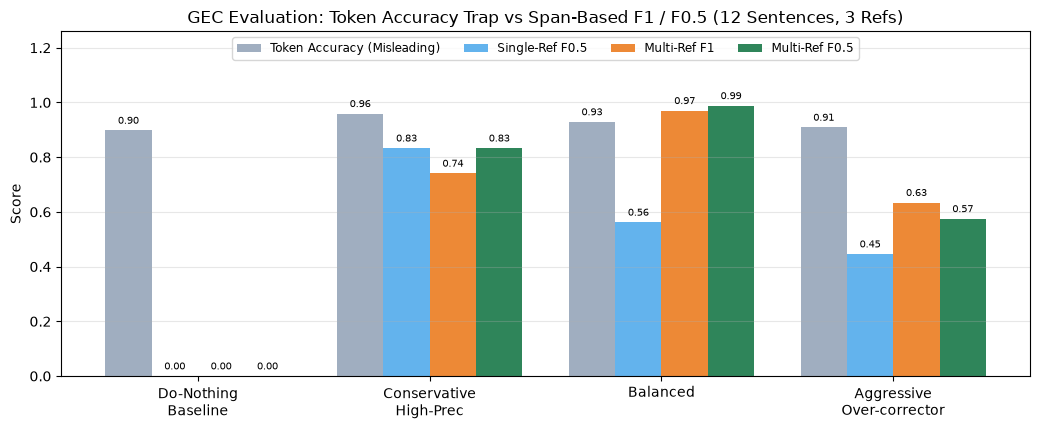

In [6]:
# 3. Token Accuracy vs Span F1 / F0.5（Single-Ref vs Multi-Ref Best-Annotator）
def span_key(ed):
    return (ed[0], ed[1], ed[3])

def compute_fbeta(tp, fp, fn, beta=0.5):
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    denom = (beta ** 2) * p + r
    f = (1.0 + beta ** 2) * p * r / denom if denom > 0 else 0.0
    return p, r, f

def token_accuracy_against_ref0(preds):
    correct = total = 0
    for it, p in zip(gec_benchmark, preds):
        pt, rt = p.split(), it["refs"][0].split()
        ops = align_tokens_dp(pt, rt)
        correct += sum(1 for op, *_ in ops if op == "match")
        total += max(len(pt), len(rt))
    return correct / total

def eval_single_ref(preds, ref_idx=0, beta=0.5):
    tp = fp = fn = 0
    for item, pred in zip(gec_benchmark, preds):
        se = {span_key(e) for e in extract_edit_spans(item["src"], pred)}
        re_ = {span_key(e) for e in extract_edit_spans(item["src"], item["refs"][ref_idx])}
        tp += len(se & re_)
        fp += len(se - re_)
        fn += len(re_ - se)
    return compute_fbeta(tp, fp, fn, beta), (tp, fp, fn)

def eval_multi_ref_best(preds, beta=0.5):
    '''ERRANT / M2Scorer 方式: コーパス F_beta を最大化する文ごとの最適アノテータ選択'''
    n = len(gec_benchmark)
    sys_sets = [{span_key(e) for e in extract_edit_spans(it["src"], p)} for it, p in zip(gec_benchmark, preds)]
    ref_sets = [[{span_key(e) for e in extract_edit_spans(it["src"], r)} for r in it["refs"]] for it in gec_benchmark]
    chosen = [0] * n
    for _ in range(10):
        changed = False
        tot_tp = sum(len(sys_sets[i] & ref_sets[i][chosen[i]]) for i in range(n))
        tot_fp = sum(len(sys_sets[i] - ref_sets[i][chosen[i]]) for i in range(n))
        tot_fn = sum(len(ref_sets[i][chosen[i]] - sys_sets[i]) for i in range(n))
        for i in range(n):
            base_tp = tot_tp - len(sys_sets[i] & ref_sets[i][chosen[i]])
            base_fp = tot_fp - len(sys_sets[i] - ref_sets[i][chosen[i]])
            base_fn = tot_fn - len(ref_sets[i][chosen[i]] - sys_sets[i])
            best_r = chosen[i]
            best_f = compute_fbeta(tot_tp, tot_fp, tot_fn, beta)[2]
            for r in range(len(ref_sets[i])):
                cand_f = compute_fbeta(
                    base_tp + len(sys_sets[i] & ref_sets[i][r]),
                    base_fp + len(sys_sets[i] - ref_sets[i][r]),
                    base_fn + len(ref_sets[i][r] - sys_sets[i]),
                    beta,
                )[2]
                if cand_f > best_f + 1e-12:
                    best_f, best_r = cand_f, r
            if best_r != chosen[i]:
                tot_tp = base_tp + len(sys_sets[i] & ref_sets[i][best_r])
                tot_fp = base_fp + len(sys_sets[i] - ref_sets[i][best_r])
                tot_fn = base_fn + len(ref_sets[i][best_r] - sys_sets[i])
                chosen[i] = best_r
                changed = True
        if not changed:
            break
    tp = sum(len(sys_sets[i] & ref_sets[i][chosen[i]]) for i in range(n))
    fp = sum(len(sys_sets[i] - ref_sets[i][chosen[i]]) for i in range(n))
    fn = sum(len(ref_sets[i][chosen[i]] - sys_sets[i]) for i in range(n))
    return compute_fbeta(tp, fp, fn, beta), (tp, fp, fn), chosen

systems = [
    ("Do-Nothing Baseline", "src"),
    ("Conservative High-Precision", "cons"),
    ("Balanced", "bal"),
    ("Aggressive Over-corrector", "aggr"),
]

gec_rows = []
bal_chosen_anns = None
for sys_name, key in systems:
    preds = [it[key] for it in gec_benchmark]
    tok_acc = token_accuracy_against_ref0(preds)
    (_, _, f1_1), _ = eval_single_ref(preds, 0, beta=1.0)
    (p1, r1, f05_1), _ = eval_single_ref(preds, 0, beta=0.5)
    (_, _, f1_m), _, _ = eval_multi_ref_best(preds, beta=1.0)
    (pm, rm, f05_m), (tp, fp, fn), chosen = eval_multi_ref_best(preds, beta=0.5)
    if key == "bal":
        bal_chosen_anns = chosen
    gec_rows.append({
        "システム": sys_name,
        "Token Acc": round(tok_acc, 3),
        "Single-Ref F1": round(f1_1, 3),
        "Single-Ref F0.5": round(f05_1, 3),
        "Multi-Ref Prec": round(pm, 3),
        "Multi-Ref Rec": round(rm, 3),
        "Multi-Ref F1": round(f1_m, 3),
        "Multi-Ref F0.5": round(f05_m, 3),
        "TP/FP/FN": f"{tp}/{fp}/{fn}",
    })

df_gec = pd.DataFrame(gec_rows)
print("=== GEC 評価指標の比較（12 文・3 人手アノテータ） ===")
display(df_gec)

# Balanced が Single-Ref では不当に減点され、Multi-Ref で救済された事例を表示
rescued_rows = []
for idx, (it, ann_id) in enumerate(zip(gec_benchmark, bal_chosen_anns), 1):
    if ann_id != 0:
        rescued_rows.append({
            "文ID": idx,
            "選択アノテータ": f"Annotator {ann_id}",
            "Balanced 出力": it["bal"],
            "Annotator 0 (参考)": it["refs"][0],
        })
print("\n=== Multi-Ref 評価で Annotator 1/2 の妥当な言い換えが救済された事例 (Balanced) ===")
display(pd.DataFrame(rescued_rows))

# 4. 英語ラベル比較プロット
fig, ax = plt.subplots(figsize=(10.5, 4.4))
x = np.arange(len(df_gec))
w = 0.2
short_labels = ["Do-Nothing\nBaseline", "Conservative\nHigh-Prec", "Balanced", "Aggressive\nOver-corrector"]
b1 = ax.bar(x - 1.5 * w, df_gec["Token Acc"], w, label="Token Accuracy (Misleading)", color="#a0aec0")
b2 = ax.bar(x - 0.5 * w, df_gec["Single-Ref F0.5"], w, label="Single-Ref F0.5", color="#63b3ed")
b3 = ax.bar(x + 0.5 * w, df_gec["Multi-Ref F1"], w, label="Multi-Ref F1", color="#ed8936")
b4 = ax.bar(x + 1.5 * w, df_gec["Multi-Ref F0.5"], w, label="Multi-Ref F0.5", color="#2f855a")

for bars in (b1, b2, b3, b4):
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.015, f"{h:.2f}", ha="center", va="bottom", fontsize=7.5)

ax.set_xticks(x, short_labels)
ax.set_ylim(0.0, 1.26)
ax.set_ylabel("Score")
ax.set_title("GEC Evaluation: Token Accuracy Trap vs Span-Based F1 / F0.5 (12 Sentences, 3 Refs)")
ax.legend(loc="upper center", ncol=4, fontsize=8.5, frameon=True)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 観察とまとめ（第 5 節）

- **Token Accuracy の罠**: 原文を一切訂正しない **Do-Nothing Baseline** でもトークン正解率は **90% 近く**（`0.90` 前後）に達しますが、編集スパン単位では **TP = 0 のため $F_{0.5} = 0.000$** となり、訂正能力の欠如を正しく見抜けます。また、`Aggressive Over-corrector` は過剰訂正のせいで Token Accuracy すら `Balanced` を下回ります。
- **$F_1$ と $F_{0.5}$ の違い（誤訂正ペナルティ）**: GEC では原文の意味や文体を壊す過剰訂正を避けるため、適合率を再現率の 2 倍重視する **$F_{0.5}$** ($\beta = 0.5$) が標準です。`Conservative`（高適合率・中再現率）と `Aggressive`（低適合率・高再現率）を比べると、$F_1$ よりも $F_{0.5}$ のほうが過剰訂正を行う `Aggressive` を厳しく評価します。
- **Single-Ref vs Multi-Ref Best-Annotator $F_{0.5}$**: `Balanced` は `visited the library`・`much homework`・`talked about`・`showed us`・`It was raining ... but` のような妥当な別解を出しているにもかかわらず、1 名のみ (Annotator 0) で評価すると誤訂正扱いされ大きく減点されます。3 名の人手参照から最適なアノテータを選ぶ **Multi-Ref Best-Annotator $F_{0.5}$** に切り替えることで、正当な訂正バリエーションが救済され、システムの真の実力が正しく評価できます。

---

## 6. 発展：ノイズあり通信路モデルによる外来語の音訳（3-3 & 4-2-2 関連論文：Knight & Graehl 1997）

第 4 節で見た「雑音のある通信路モデル (Noisy Channel Model)」はスペル訂正だけでなく、カタカナ外来語を元の英語表記へ逆変換する**音訳** (Transliteration; Knight & Graehl, ACL 1997) にもそのまま応用できます。

生成過程では、英語単語列 $e$（事前確率 $P_{\text{LM}}(e)$）が英語音素列 $p$ を経由して日本語カタカナモーラ列 $k$ へ変換されます。ベイズ則により、観測されたカタカナ $k$ から最も確からしい元の英語表現 $\hat{e}$ を復元します。

$$\hat{e} = \arg\max_{e} P(e \mid k) = \arg\max_{e} P_{\text{LM}}(e)\, P_{\text{trans}}(k \mid e)$$

素朴な「ヘボン式ローマ字化 ＋ 英語綴りとの Levenshtein 距離」が破綻する主な理由は次の 3 点です。
1. **英語の綴りと発音の乖離**: `chocolate` の黙字 `e` や `ch=/tʃ/`、`algorithm` の `th`、複数語 `ice cream` の空白など。
2. **日本語の音韻制約（挿入母音と音素統合）**: 子音連続や語末子音に `u`/`o`/`i` が挿入され（`ice cream` → `アイスクリーム`）、`L/R` がどちらもラ行へ、`B/V` がバ行へ合流する（`violin` → `バイオリン`）。
3. **同音・類似音候補の曖昧性**: `crown` vs `clown`（どちらも `クラウン`）、`ice cream` vs `ice clean`、`chocolate` vs `chalk late` のように音韻変換だけでは区別できない候補を、英語言語モデル $P_{\text{LM}}(e)$ が救済します。

In [7]:
DIGRAPHS = {
    "キャ": "kya", "キュ": "kyu", "キョ": "kyo",
    "ギャ": "gya", "ギュ": "gyu", "ギョ": "gyo",
    "シャ": "sha", "シュ": "shu", "シェ": "she", "ショ": "sho",
    "ジャ": "ja",  "ジュ": "ju",  "ジェ": "je",  "ジョ": "jo",
    "チャ": "cha", "チュ": "chu", "チェ": "che", "チョ": "cho",
    "ニャ": "nya", "ニュ": "nyu", "ニョ": "nyo",
    "ヒャ": "hya", "ヒュ": "hyu", "ヒョ": "hyo",
    "ビャ": "bya", "ビュ": "byu", "ビョ": "byo",
    "ピャ": "pya", "ピュ": "pyu", "ピョ": "pyo",
    "ミャ": "mya", "ミュ": "myu", "ミョ": "myo",
    "リャ": "rya", "リュ": "ryu", "リョ": "ryo",
    "ファ": "fa",  "フィ": "fi",  "フェ": "fe",  "フォ": "fo",
    "ヴァ": "va",  "ヴィ": "vi",  "ヴェ": "ve",  "ヴォ": "vo",
    "ティ": "ti",  "ディ": "di",  "テュ": "tyu", "デュ": "dyu",
    "ウィ": "wi",  "ウェ": "we",  "ウォ": "wo",
}

MONOGRAPHS = {
    "ア": "a", "イ": "i", "ウ": "u", "エ": "e", "オ": "o",
    "カ": "ka", "キ": "ki", "ク": "ku", "ケ": "ke", "コ": "ko",
    "ガ": "ga", "ギ": "gi", "グ": "gu", "ゲ": "ge", "ゴ": "go",
    "サ": "sa", "シ": "shi", "ス": "su", "セ": "se", "ソ": "so",
    "ザ": "za", "ジ": "ji", "ズ": "zu", "ゼ": "ze", "ゾ": "zo",
    "タ": "ta", "チ": "chi", "ツ": "tsu", "テ": "te", "ト": "to",
    "ダ": "da", "ヂ": "ji", "ヅ": "zu", "デ": "de", "ド": "do",
    "ナ": "na", "ニ": "ni", "ヌ": "nu", "ネ": "ne", "ノ": "no",
    "ハ": "ha", "ヒ": "hi", "フ": "fu", "ヘ": "he", "ホ": "ho",
    "バ": "ba", "ビ": "bi", "ブ": "bu", "ベ": "be", "ボ": "bo",
    "パ": "pa", "ピ": "pi", "プ": "pu", "ペ": "pe", "ポ": "po",
    "マ": "ma", "ミ": "mi", "ム": "mu", "メ": "me", "モ": "mo",
    "ヤ": "ya", "ユ": "yu", "ヨ": "yo",
    "ラ": "ra", "リ": "ri", "ル": "ru", "レ": "re", "ロ": "ro",
    "ワ": "wa", "ヲ": "o", "ン": "n", "ヴ": "vu",
}

MORA_PHONEMES = {
    "ア": ["a"], "イ": ["i"], "ウ": ["u"], "エ": ["e"], "オ": ["o"],
    "カ": ["k", "a"], "キ": ["k", "i"], "ク": ["k", "u"], "ケ": ["k", "e"], "コ": ["k", "o"],
    "ガ": ["g", "a"], "ギ": ["g", "i"], "グ": ["g", "u"], "ゲ": ["g", "e"], "ゴ": ["g", "o"],
    "キャ": ["k", "y", "a"], "キュ": ["k", "y", "u"], "キョ": ["k", "y", "o"],
    "ギャ": ["g", "y", "a"], "ギュ": ["g", "y", "u"], "ギョ": ["g", "y", "o"],
    "サ": ["s", "a"], "シ": ["sh", "i"], "ス": ["s", "u"], "セ": ["s", "e"], "ソ": ["s", "o"],
    "ザ": ["z", "a"], "ジ": ["jh", "i"], "ズ": ["z", "u"], "ゼ": ["z", "e"], "ゾ": ["z", "o"],
    "シャ": ["sh", "a"], "シュ": ["sh", "u"], "シェ": ["sh", "e"], "ショ": ["sh", "o"],
    "ジャ": ["jh", "a"], "ジュ": ["jh", "u"], "ジェ": ["jh", "e"], "ジョ": ["jh", "o"],
    "タ": ["t", "a"], "チ": ["ch", "i"], "ツ": ["ts", "u"], "テ": ["t", "e"], "ト": ["t", "o"],
    "ダ": ["d", "a"], "ヂ": ["jh", "i"], "ヅ": ["z", "u"], "デ": ["d", "e"], "ド": ["d", "o"],
    "チャ": ["ch", "a"], "チュ": ["ch", "u"], "チェ": ["ch", "e"], "チョ": ["ch", "o"],
    "ティ": ["t", "i"], "ディ": ["d", "i"], "テュ": ["t", "y", "u"], "デュ": ["d", "y", "u"],
    "ナ": ["n", "a"], "ニ": ["n", "i"], "ヌ": ["n", "u"], "ネ": ["n", "e"], "ノ": ["n", "o"],
    "ニャ": ["n", "y", "a"], "ニュ": ["n", "y", "u"], "ニョ": ["n", "y", "o"],
    "ハ": ["h", "a"], "ヒ": ["h", "i"], "フ": ["f", "u"], "ヘ": ["h", "e"], "ホ": ["h", "o"],
    "ヒャ": ["h", "y", "a"], "ヒュ": ["h", "y", "u"], "ヒョ": ["h", "y", "o"],
    "ファ": ["f", "a"], "フィ": ["f", "i"], "フェ": ["f", "e"], "フォ": ["f", "o"],
    "バ": ["b", "a"], "ビ": ["b", "i"], "ブ": ["b", "u"], "ベ": ["b", "e"], "ボ": ["b", "o"],
    "ビャ": ["b", "y", "a"], "ビュ": ["b", "y", "u"], "ビョ": ["b", "y", "o"],
    "ヴァ": ["v", "a"], "ヴィ": ["v", "i"], "ヴ": ["v", "u"], "ヴェ": ["v", "e"], "ヴォ": ["v", "o"],
    "パ": ["p", "a"], "ピ": ["p", "i"], "プ": ["p", "u"], "ペ": ["p", "e"], "ポ": ["p", "o"],
    "ピャ": ["p", "y", "a"], "ピュ": ["p", "y", "u"], "ピョ": ["p", "y", "o"],
    "マ": ["m", "a"], "ミ": ["m", "i"], "ム": ["m", "u"], "メ": ["m", "e"], "モ": ["m", "o"],
    "ミャ": ["m", "y", "a"], "ミュ": ["m", "y", "u"], "ミョ": ["m", "y", "o"],
    "ヤ": ["y", "a"], "ユ": ["y", "u"], "ヨ": ["y", "o"],
    "ラ": ["r", "a"], "リ": ["r", "i"], "ル": ["r", "u"], "レ": ["r", "e"], "ロ": ["r", "o"],
    "リャ": ["r", "y", "a"], "リュ": ["r", "y", "u"], "リョ": ["r", "y", "o"],
    "ワ": ["w", "a"], "ウィ": ["w", "i"], "ウェ": ["w", "e"], "ウォ": ["w", "o"],
    "ン": ["N"], "ッ": ["Q"], "ー": [":"],
}

def katakana_to_moras(kata):
    moras, i = [], 0
    while i < len(kata):
        if i + 1 < len(kata) and kata[i:i + 2] in DIGRAPHS:
            moras.append(kata[i:i + 2])
            i += 2
        else:
            moras.append(kata[i])
            i += 1
    return moras

def katakana_to_romaji(kata):
    moras = katakana_to_moras(kata)
    out = []
    for idx, m in enumerate(moras):
        if m == "ッ" and idx + 1 < len(moras):
            nxt = DIGRAPHS.get(moras[idx + 1], MONOGRAPHS.get(moras[idx + 1], ""))
            if nxt:
                out.append(nxt[0])
        elif m == "ー" and out and out[-1]:
            out.append(out[-1][-1])
        else:
            out.append(DIGRAPHS.get(m, MONOGRAPHS.get(m, m)))
    return "".join(out)

def katakana_to_jp_units(kata):
    return [(u, m) for m in katakana_to_moras(kata) for u in MORA_PHONEMES[m]]

# 英語候補単語の発音辞書（ARPAbet 風音素列）
PRON_LEXICON = {
    "ice": ["AY", "S"], "cream": ["K", "R", "IY", "M"],
    "application": ["AE", "P", "L", "IH", "K", "EY", "SH", "AH", "N"],
    "algorithm": ["AE", "L", "G", "ER", "IH", "DH", "AH", "M"],
    "computer": ["K", "AH", "M", "P", "Y", "UW", "T", "ER"],
    "chocolate": ["CH", "AA", "K", "L", "AH", "T"],
    "internet": ["IH", "N", "T", "ER", "N", "EH", "T"],
    "download": ["D", "AW", "N", "L", "OW", "D"],
    "battery": ["B", "AE", "T", "ER", "IY"],
    "professional": ["P", "R", "AH", "F", "EH", "SH", "AH", "N", "AH", "L"],
    "restaurant": ["R", "EH", "S", "T", "R", "AA", "N", "T"],
    "cloud": ["K", "L", "AW", "D"], "best": ["B", "EH", "S", "T"],
    "glass": ["G", "L", "AE", "S"], "crown": ["K", "R", "AW", "N"],
    "violin": ["V", "AY", "AH", "L", "IH", "N"],
    # 紛らわしい音韻・綴り干渉候補
    "clean": ["K", "L", "IY", "N"], "gleam": ["G", "L", "IY", "M"],
    "eyes": ["AY", "Z"], "a": ["AH"], "scream": ["S", "K", "R", "IY", "M"], "crate": ["K", "R", "EY", "T"],
    "appreciation": ["AH", "P", "R", "IY", "SH", "IY", "EY", "SH", "AH", "N"],
    "replication": ["R", "EH", "P", "L", "IH", "K", "EY", "SH", "AH", "N"],
    "implication": ["IH", "M", "P", "L", "IH", "K", "EY", "SH", "AH", "N"],
    "logarithm": ["L", "AO", "G", "ER", "IH", "DH", "AH", "M"],
    "algal": ["AE", "L", "G", "AH", "L"], "rhythm": ["R", "IH", "DH", "AH", "M"],
    "allergy": ["AE", "L", "ER", "JH", "IY"],
    "commuter": ["K", "AH", "M", "Y", "UW", "T", "ER"],
    "composter": ["K", "AH", "M", "P", "OW", "S", "T", "ER"],
    "competitor": ["K", "AH", "M", "P", "EH", "T", "IH", "T", "ER"],
    "chalk": ["CH", "AO", "K"], "late": ["L", "EY", "T"],
    "choke": ["CH", "OW", "K"], "rate": ["R", "EY", "T"], "check": ["CH", "EH", "K"],
    "intranet": ["IH", "N", "T", "R", "AH", "N", "EH", "T"],
    "inter": ["IH", "N", "T", "ER"], "net": ["N", "EH", "T"], "interact": ["IH", "N", "T", "ER", "AE", "K", "T"],
    "down": ["D", "AW", "N"], "road": ["R", "OW", "D"], "load": ["L", "OW", "D"],
    "dawn": ["D", "AO", "N"], "loud": ["L", "AW", "D"],
    "buttery": ["B", "AH", "T", "ER", "IY"], "vat": ["V", "AE", "T"], "tree": ["T", "R", "IY"],
    "pastry": ["P", "EY", "S", "T", "R", "IY"], "flattery": ["F", "L", "AE", "T", "ER", "IY"],
    "processional": ["P", "R", "AH", "S", "EH", "SH", "AH", "N", "AH", "L"],
    "confessional": ["K", "AH", "N", "F", "EH", "SH", "AH", "N", "AH", "L"],
    "restraint": ["R", "IH", "S", "T", "R", "EY", "N", "T"],
    "rest": ["R", "EH", "S", "T"], "run": ["R", "AH", "N"], "land": ["L", "AE", "N", "D"],
    "crowd": ["K", "R", "AW", "D"], "clout": ["K", "L", "AW", "T"],
    "vest": ["V", "EH", "S", "T"], "bust": ["B", "AH", "S", "T"], "pest": ["P", "EH", "S", "T"],
    "grass": ["G", "R", "AE", "S"], "clown": ["K", "L", "AW", "N"], "clone": ["K", "L", "OW", "N"],
    "baron": ["B", "EH", "R", "AH", "N"], "bionic": ["B", "AY", "AA", "N", "IH", "K"], "byron": ["B", "AY", "R", "AH", "N"],
}

CANDIDATES = [
    "ice cream", "application", "algorithm", "computer", "chocolate",
    "internet", "download", "battery", "professional", "restaurant",
    "cloud", "best", "glass", "crown", "violin",
    "ice clean", "eyes cream", "ice gleam", "a scream", "ice crate",
    "appreciation", "replication", "implication",
    "logarithm", "algal rhythm", "allergy rhythm",
    "commuter", "composter", "competitor",
    "chalk late", "choke rate", "check late",
    "intranet", "inter net", "interact",
    "down road", "down load", "dawn load", "down loud",
    "buttery", "vat tree", "pastry", "flattery",
    "processional", "confessional",
    "restraint", "rest run", "rest land",
    "crowd", "clout", "vest", "bust", "pest", "rest", "grass", "clown", "clone",
    "baron", "bionic", "byron",
]

ENGLISH_CORPUS = [
    "i like chocolate ice cream after dinner at a restaurant",
    "she ordered vanilla ice cream and hot chocolate at the restaurant",
    "we ate ice cream near the restaurant",
    "the chef at the restaurant made chocolate cake and ice cream",
    "he drank water from a clear glass at the restaurant",
    "please pass me that glass on the table",
    "a broken glass was on the floor",
    "the king wore a golden crown on his head",
    "the royal crown was displayed in the museum",
    "this software application runs on a computer over the internet",
    "you can download the mobile application from the cloud",
    "every computer needs a fast internet connection and cloud storage",
    "the new algorithm improved the computer application speed",
    "this sorting algorithm runs on any modern computer",
    "please download the update before the battery runs low",
    "my laptop computer has a long battery life",
    "replace the old battery in the computer",
    "the cloud platform connects over the internet for fast download",
    "the best professional engineers design a clean algorithm",
    "he gave his best performance as a professional musician on the violin",
    "she played the violin beautifully at the concert near the restaurant",
    "the best restaurant in town serves fresh chocolate ice cream",
    "the application uses a cloud database and an internet api",
    "the crowd watched the clown at the circus",
    "a dark cloud covered the sky over the green grass",
    "he put on a warm vest over his shirt",
    "do not touch the hot vat or the rest of the tools",
    "the commuter took the train with a cup of tea",
    "show restraint when evaluating the processional march",
    "the appreciation of replication studies is growing",
]

uni_cnt = Counter()
bi_cnt = defaultdict(Counter)
lm_vocab = set()
for sent in ENGLISH_CORPUS:
    toks = ["<s>"] + sent.split() + ["</s>"]
    lm_vocab.update(toks)
    for i, tok in enumerate(toks):
        uni_cnt[tok] += 1
        if i > 0:
            bi_cnt[toks[i - 1]][tok] += 1
for cand in CANDIDATES:
    lm_vocab.update(cand.split())
TOTAL_LM = sum(uni_cnt.values())
V_LM = len(lm_vocab)

def lm_log_prob(phrase, k=0.25):
    toks = phrase.split()
    lp = math.log((uni_cnt[toks[0]] + k) / (TOTAL_LM + k * V_LM))
    for i in range(1, len(toks)):
        lp += math.log((bi_cnt[toks[i - 1]][toks[i]] + k) / (uni_cnt[toks[i - 1]] + k * V_LM))
    return lp

EN_TO_JP_1TO1 = {
    ("P", "p"): 0.0, ("B", "b"): 0.0, ("T", "t"): 0.0, ("D", "d"): 0.0,
    ("K", "k"): 0.0, ("G", "g"): 0.0, ("M", "m"): 0.0, ("N", "n"): 0.0, ("N", "N"): 0.0, ("M", "N"): 0.8,
    ("S", "s"): 0.0, ("S", "sh"): 0.6, ("Z", "z"): 0.0, ("Z", "jh"): 0.5,
    ("SH", "sh"): 0.0, ("CH", "ch"): 0.0, ("JH", "jh"): 0.0,
    ("F", "f"): 0.0, ("F", "h"): 0.4, ("V", "v"): 0.0, ("V", "b"): 0.15,
    ("TH", "s"): 0.2, ("DH", "z"): 0.2, ("DH", "d"): 0.5,
    ("R", "r"): 0.1, ("L", "r"): 0.1,
    ("Y", "y"): 0.0, ("W", "w"): 0.0, ("HH", "h"): 0.0,
    ("AA", "a"): 0.05, ("AA", "o"): 0.1, ("AE", "a"): 0.05, ("AH", "a"): 0.05, ("AH", "o"): 0.3, ("AH", "u"): 0.3, ("AH", "e"): 0.4,
    ("AO", "o"): 0.05, ("AO", "a"): 0.4, ("EH", "e"): 0.05, ("IH", "i"): 0.05, ("IY", "i"): 0.05,
    ("UH", "u"): 0.05, ("UW", "u"): 0.05, ("ER", "a"): 0.15, ("ER", "r"): 0.15, ("ER", "e"): 0.4,
    ("EY", "e"): 0.2, ("OW", "o"): 0.15, ("AY", "a"): 0.5, ("AW", "a"): 0.5,
}
EN_TO_JP_1TO2 = {
    ("AY", ("a", "i")): 0.0, ("EY", ("e", "i")): 0.0, ("EY", ("e", ":")): 0.1,
    ("OW", ("o", ":")): 0.05, ("OW", ("o", "u")): 0.05, ("AW", ("a", "u")): 0.0,
    ("IY", ("i", ":")): 0.05, ("UW", ("u", ":")): 0.05, ("AO", ("o", ":")): 0.05, ("ER", ("a", ":")): 0.05,
    ("P", ("Q", "p")): 0.15, ("T", ("Q", "t")): 0.15, ("K", ("Q", "k")): 0.15,
    ("CH", ("Q", "ch")): 0.2, ("S", ("Q", "s")): 0.2,
}
EPENTHETIC_VOWELS = {"u": 0.15, "o": 0.22, "i": 0.25, "a": 0.6, "e": 0.6, ":": 0.25}

def get_phrase_phonemes(phrase):
    return [p for w in phrase.split() for p in PRON_LEXICON[w]]

def phonological_dp(en_ph, jp_units, return_alignment=False):
    m, n = len(en_ph), len(jp_units)
    INF = 1e9
    dp = np.full((m + 1, n + 1), INF)
    bp = [[None] * (n + 1) for _ in range(m + 1)]
    dp[0, 0] = 0.0
    for i in range(m + 1):
        for j in range(n + 1):
            cur = dp[i, j]
            if cur >= INF:
                continue
            if j < n:
                u, mora = jp_units[j]
                c = cur + EPENTHETIC_VOWELS.get(u, 2.2)
                if c < dp[i, j + 1]:
                    dp[i, j + 1], bp[i][j + 1] = c, (i, j, f"eps -> {u}({mora})")
            if i < m:
                c = cur + (1.4 if en_ph[i] in {"R", "T", "D", "AH", "HH"} else 2.4)
                if c < dp[i + 1, j]:
                    dp[i + 1, j], bp[i + 1][j] = c, (i, j, f"{en_ph[i]} -> eps")
            if i < m and j < n:
                u, mora = jp_units[j]
                c = cur + EN_TO_JP_1TO1.get((en_ph[i], u), 3.0)
                if c < dp[i + 1, j + 1]:
                    dp[i + 1, j + 1], bp[i + 1][j + 1] = c, (i, j, f"{en_ph[i]} -> {u}({mora})")
            if i < m and j + 1 < n:
                u1, m1 = jp_units[j]
                u2, m2 = jp_units[j + 1]
                cost2 = EN_TO_JP_1TO2.get((en_ph[i], (u1, u2)))
                if cost2 is not None and cur + cost2 < dp[i + 1, j + 2]:
                    dp[i + 1, j + 2], bp[i + 1][j + 2] = cur + cost2, (i, j, f"{en_ph[i]} -> {u1}{u2}({m1}{m2})")
    if not return_alignment:
        return float(dp[m, n])
    path, ci, cj = [], m, n
    while ci > 0 or cj > 0:
        pi, pj, lbl = bp[ci][cj]
        path.append(lbl)
        ci, cj = pi, pj
    path.reverse()
    return float(dp[m, n]), path

,カタカナ,正解,1. ローマ字+Lev,1順位,2. 音韻DPのみ,2順位,3. Noisy Channel,3順位
0,アイスクリーム,ice cream,a scream,3,ice cream,1,ice cream,1
1,アプリケーション,application,application,1,application,1,application,1
2,アルゴリズム,algorithm,algorithm,1,algorithm,1,algorithm,1
3,コンピューター,computer,computer,1,computer,1,computer,1
4,チョコレート,chocolate,choke rate,2,chalk late,3,chocolate,1
5,インターネット,internet,intranet,3,inter net,2,internet,1
6,ダウンロード,download,dawn load,5,down load,3,download,1
7,バッテリー,battery,battery,1,battery,1,battery,1
8,プロフェッショナル,professional,professional,1,professional,1,professional,1
9,レストラン,restaurant,rest run,3,rest run,3,restaurant,1


,モデル,Top-1 Accuracy,Top-3 Accuracy,MRR
0,1. Naive Romaji + Levenshtein,0.467,0.933,0.658
1,2. Phonological DP (Channel only),0.667,1.000,0.800
2,3. Full Noisy Channel (DP + LM),1.000,1.000,1.000


--- DP 最適アライメント経路（バックトレース） ---
アイスクリーム -> 'ice cream' (cost=0.60): AY -> ai(アイ) | S -> s(ス) | eps -> u(ス) | K -> k(ク) | eps -> u(ク) | R -> r(リ) | IY -> i:(リー) | M -> m(ム) | eps -> u(ム)
バイオリン -> 'violin' (cost=0.60): V -> b(バ) | AY -> ai(バイ) | AH -> o(オ) | L -> r(リ) | IH -> i(リ) | N -> N(ン)
アルゴリズム -> 'algorithm' (cost=1.37): AE -> a(ア) | L -> r(ル) | eps -> u(ル) | G -> g(ゴ) | eps -> o(ゴ) | ER -> r(リ) | IH -> i(リ) | DH -> z(ズ) | AH -> u(ズ) | M -> m(ム) | eps -> u(ム)


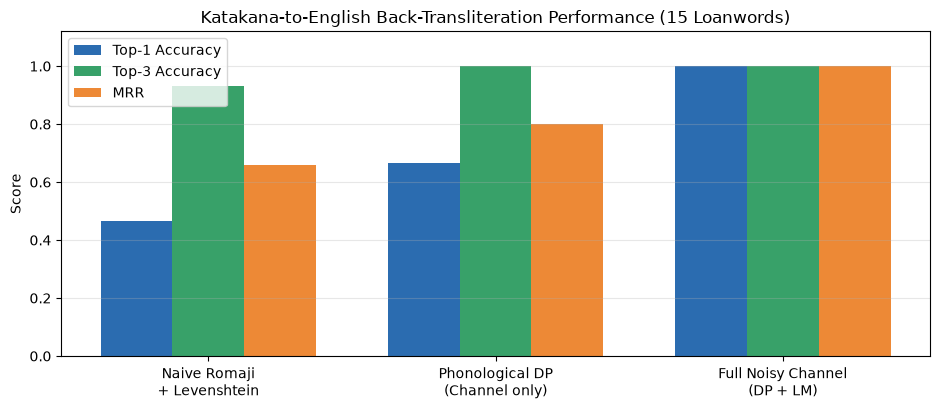

In [8]:
TEST_LOANWORDS = [
    ("アイスクリーム", "ice cream"),
    ("アプリケーション", "application"),
    ("アルゴリズム", "algorithm"),
    ("コンピューター", "computer"),
    ("チョコレート", "chocolate"),
    ("インターネット", "internet"),
    ("ダウンロード", "download"),
    ("バッテリー", "battery"),
    ("プロフェッショナル", "professional"),
    ("レストラン", "restaurant"),
    ("クラウド", "cloud"),
    ("ベスト", "best"),
    ("グラス", "glass"),
    ("クラウン", "crown"),
    ("バイオリン", "violin"),
]

ALPHA_CH = 2.5
BETA_LM = 0.6

eval_rows = []
for kata, gold in TEST_LOANWORDS:
    rom = katakana_to_romaji(kata)
    jp_u = katakana_to_jp_units(kata)

    rank1 = sorted(CANDIDATES, key=lambda c: (levenshtein_dp(rom, c.replace(" ", ""))[0], c))
    rank2 = sorted(CANDIDATES, key=lambda c: (round(phonological_dp(get_phrase_phonemes(c), jp_u), 4), c))
    rank3 = sorted(
        CANDIDATES,
        key=lambda c: (-(-ALPHA_CH * phonological_dp(get_phrase_phonemes(c), jp_u) + BETA_LM * lm_log_prob(c)), c),
    )
    eval_rows.append({
        "カタカナ": kata,
        "正解": gold,
        "1. ローマ字+Lev": rank1[0],
        "1順位": rank1.index(gold) + 1,
        "2. 音韻DPのみ": rank2[0],
        "2順位": rank2.index(gold) + 1,
        "3. Noisy Channel": rank3[0],
        "3順位": rank3.index(gold) + 1,
    })

res_tl = pd.DataFrame(eval_rows)
display(res_tl)

metric_rows = []
for name, col in [
    ("1. Naive Romaji + Levenshtein", "1順位"),
    ("2. Phonological DP (Channel only)", "2順位"),
    ("3. Full Noisy Channel (DP + LM)", "3順位"),
]:
    ranks = res_tl[col]
    metric_rows.append({
        "モデル": name,
        "Top-1 Accuracy": round(float((ranks == 1).mean()), 3),
        "Top-3 Accuracy": round(float((ranks <= 3).mean()), 3),
        "MRR": round(float((1.0 / ranks).mean()), 3),
    })

df_tl_metrics = pd.DataFrame(metric_rows)
display(df_tl_metrics)

print("--- DP 最適アライメント経路（バックトレース） ---")
for kata, gold in [("アイスクリーム", "ice cream"), ("バイオリン", "violin"), ("アルゴリズム", "algorithm")]:
    c, path = phonological_dp(get_phrase_phonemes(gold), katakana_to_jp_units(kata), return_alignment=True)
    print(f"{kata} -> '{gold}' (cost={c:.2f}): {' | '.join(path)}")

# 英語ラベル比較プロット
fig, ax = plt.subplots(figsize=(9.5, 4.2))
x = np.arange(len(df_tl_metrics))
w = 0.25
ax.bar(x - w, df_tl_metrics["Top-1 Accuracy"], w, label="Top-1 Accuracy", color="#2b6cb0")
ax.bar(x, df_tl_metrics["Top-3 Accuracy"], w, label="Top-3 Accuracy", color="#38a169")
ax.bar(x + w, df_tl_metrics["MRR"], w, label="MRR", color="#ed8936")
ax.set_xticks(x)
ax.set_xticklabels(["Naive Romaji\n+ Levenshtein", "Phonological DP\n(Channel only)", "Full Noisy Channel\n(DP + LM)"])
ax.set_ylim(0.0, 1.12)
ax.set_ylabel("Score")
ax.set_title("Katakana-to-English Back-Transliteration Performance (15 Loanwords)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 観察とまとめ（第 6 節）

- **ローマ字＋綴り Levenshtein 距離**は、挿入母音・黙字・`v`/`b` や `l`/`r` の差異により `アイスクリーム → a scream`、`チョコレート → choke rate`、`バイオリン → baron` などの誤り（Top-1 Accuracy **0.467**、MRR **0.658**）を起こします。
- **音韻 DP アライメントのみ**では、`アイスクリーム` の最適経路 `AY -> ai(アイ) | S -> s(ス) | eps -> u(ス) | K -> k(ク) | eps -> u(ク) | R -> r(リ) | IY -> i:(リー) | M -> m(ム) | eps -> u(ム)` のように挿入母音や長音・`V/B` 変換を正しく扱えますが、言語モデルがないため `クラウン → clown`、`チョコレート → chalk late`、`インターネット → inter net`、`ダウンロード → down load`、`レストラン → rest run` など音韻的に近い・一致する候補を選び切れません（Top-1 Accuracy **0.667**、Top-3 **1.000**、MRR **0.800**）。
- **英語言語モデルを統合した Noisy Channel モデル**では、音韻通信路モデル $P_{\text{trans}}(k \mid e)$ と単語・バイグラム事前確率 $P_{\text{LM}}(e)$ の双方により、全 15 語を正しく 1 位で復元できました（Top-1 Accuracy **1.000**、MRR **1.000**）。